In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

In [2]:
titanic = sns.load_dataset('titanic')

titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
titanic.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [ ]:
# 1 Choix des colonnes/features pertinentes

features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']

X = titanic[features]
y = titanic['survived'].values

In [ ]:
# 2 Separer les données entre Train et Test

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
# 3 Gestion des valeurs manquantes

age_median = X_train['age'].median()
embarked_mode = X_train['embarked'].mode()[0]

X_train = X_train.fillna({'age': age_median, 'embarked': embarked_mode})
X_test = X_test.fillna({'age': age_median, 'embarked': embarked_mode})

print("Valeurs manquantes restantes (X_train, X_test) :", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Valeurs manquantes restantes (X_train, X_test) : 0 0


In [11]:
# 4 Encoder les variables catégorielles

cat = ['sex', 'embarked', 'pclass']
X_train = pd.get_dummies(X_train, columns=cat, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train.head()

,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,pclass_2,pclass_3
692,28.5,0,0,56.4958,True,False,True,False,True
481,28.5,0,0,0.0000,True,False,True,True,False
527,28.5,0,0,221.7792,True,False,True,False,False
855,18.0,0,1,9.3500,False,False,True,False,True
801,31.0,1,1,26.2500,False,False,True,True,False


In [12]:
# 5 Normaliser les features numeriques

num = ['age', 'fare']
scaler = StandardScaler()
X_train[num] = scaler.fit_transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])

X_train.head()

,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,pclass_2,pclass_3
692,-0.081135,0,0,0.513812,True,False,True,False,True
481,-0.081135,0,0,-0.662563,True,False,True,True,False
527,-0.081135,0,0,3.955399,True,False,True,False,False
855,-0.887827,0,1,-0.467874,False,False,True,False,True
801,0.110934,1,1,-0.115977,False,False,True,True,False


In [13]:
# 6 Conversion en numpy array

features_names = list(X_train.columns)
X_train = X_train.values.astype('float32')
X_test = X_test.values.astype('float32')

In [14]:
# 7 Verifier les dimensions

print("Shape X_train : ", X_train.shape)
print("Shape y_train : ", y_train.shape)
print("Shape X_test : ", X_test.shape)


Shape X_train :  (712, 9)
Shape y_train :  (712,)
Shape X_test :  (179, 9)


In [15]:
# 8 Construire le modele

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(27, activation='relu'),
    Dense(1, activation='sigmoid')
])

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 27)             │           270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            28 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 298 (1.16 KB)

 Trainable params: 298 (1.16 KB)

 Non-trainable params: 0 (0.00 B)

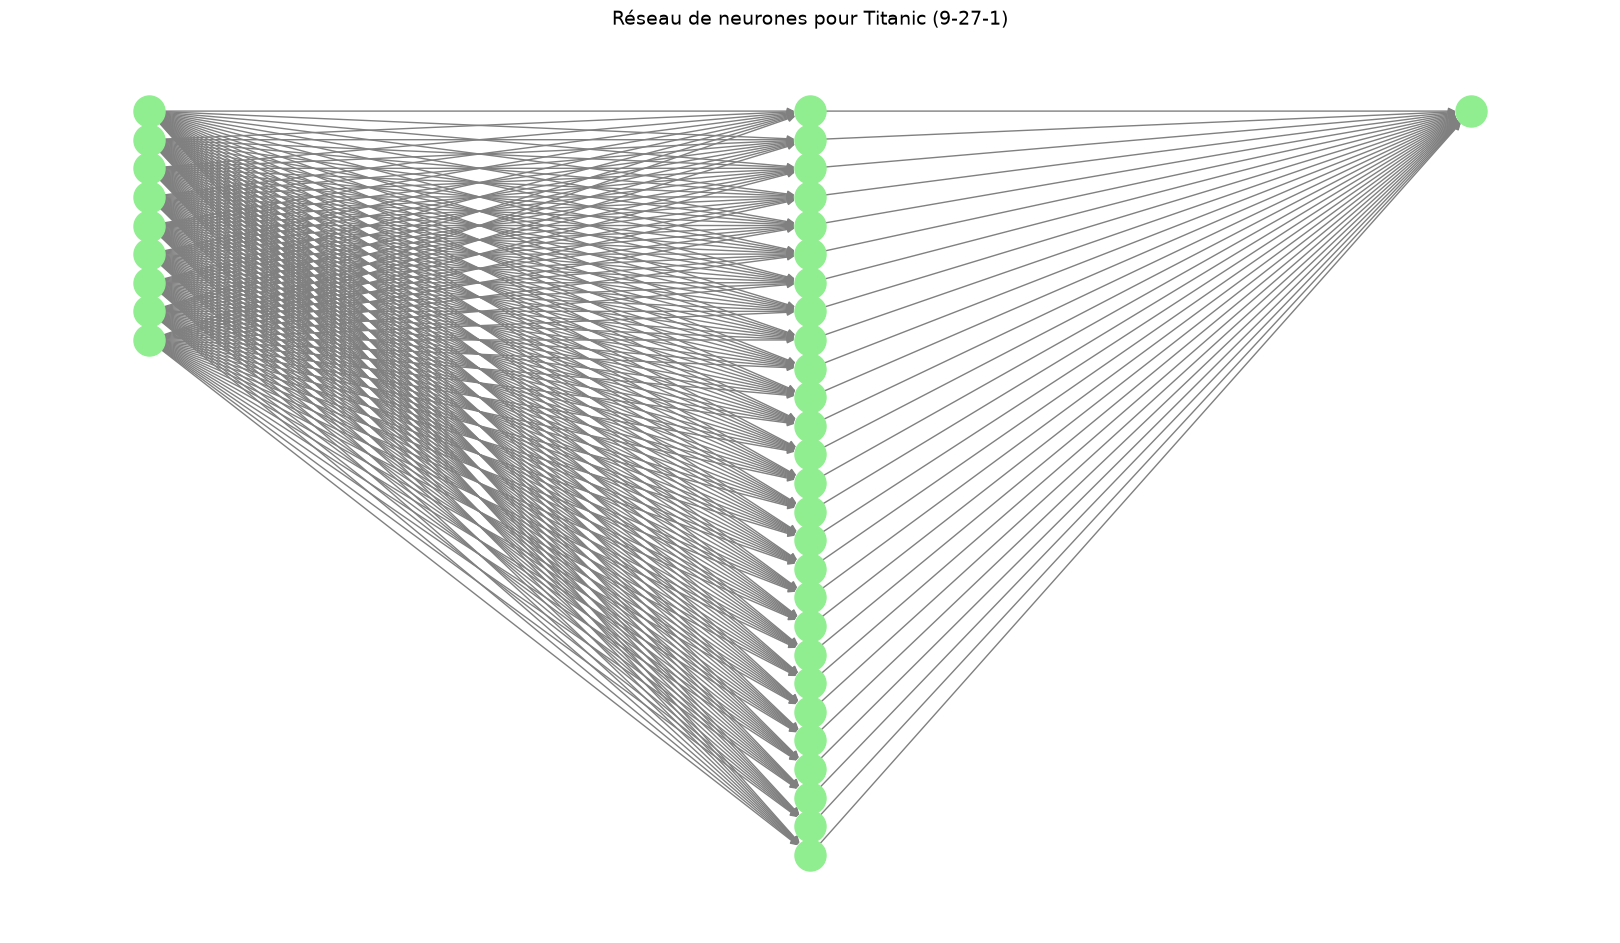

In [17]:
layers = [9, 27, 1]
G = nx.DiGraph()
pos = {}
layer_positions = []

for l, n_neurons in enumerate(layers):
    layer_pos = []
    for i in range(n_neurons):
        node_id = f"L{l}N{i}"
        G.add_node(node_id, layer=l)
        pos[node_id] = (l, -i) # Positionnner les neurones en colonnes
        layer_pos.append(node_id)
    layer_positions.append(layer_pos)

for l in range(len(layers) - 1):
    for src in layer_positions[l]:
        for dst in layer_positions[l + 1]:
            G.add_edge(src, dst)

plt.figure(figsize=(16 ,9))
nx.draw(G, pos, with_labels=False, node_size=500, node_color="lightgreen", edge_color="gray")
plt.title("Réseau de neurones pour Titanic (9-27-1)", fontsize=14)
plt.show()

In [18]:
# 9 Compiler et Entrainer le modele

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [19]:
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.1, callbacks=[early_stop])

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5359 - loss: 0.7170 - val_accuracy: 0.6111 - val_loss: 0.6429
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7063 - loss: 0.6605 - val_accuracy: 0.7917 - val_loss: 0.6031
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7344 - loss: 0.6223 - val_accuracy: 0.8056 - val_loss: 0.5742
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7297 - loss: 0.5947 - val_accuracy: 0.7778 - val_loss: 0.5518
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7234 - loss: 0.5736 - val_accuracy: 0.7917 - val_loss: 0.5326
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7375 - loss: 0.5568 - val_accuracy: 0.7917 - val_loss: 0.5169
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7484 - loss: 0.5427 - val_accuracy: 0.7778 - val_loss: 0.5036
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7547 - loss: 0.5306 - val_accuracy: 0.7778 - val_loss

In [21]:
# 10 Evaluer le modele sur le test set

loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy*100:.2f}%")

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8156 - loss: 0.4529 
Test Accuracy: 81.56%


In [23]:
predictions = model.predict(X_test)
y_pred = (predictions > 0.5).astype(int).ravel()

df_test = pd.DataFrame(X_test, columns=features_names)
df_test[num] = scaler.inverse_transform(df_test[num])

df_test['age'] = df_test['age'].round(0).astype(int)
df_test['sibsp'] = df_test['sibsp'].astype(int)
df_test['parch'] = df_test['parch'].astype(int)
df_test['fare'] = df_test['fare'].round(2)

df_test["True Class"] = y_test
df_test["Predicted Class"] = y_pred
df_test["Proba"] = predictions.ravel().round(3)
df_test["correct"] = df_test["True Class"] == df_test["Predicted Class"]

df_test.head(10)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,pclass_2,pclass_3,True Class,Predicted Class,Proba,correct
0,24,2,0,24.150000,1.0,0.0,1.0,0.0,1.0,0,0,0.131,True
1,44,0,1,16.100000,1.0,0.0,1.0,0.0,1.0,0,0,0.066,True
2,22,0,0,7.230000,1.0,0.0,0.0,0.0,1.0,1,0,0.230,False
3,41,2,0,14.110000,1.0,0.0,1.0,0.0,1.0,0,0,0.127,True
4,28,1,0,15.500000,0.0,1.0,0.0,0.0,1.0,1,1,0.705,True
5,36,1,0,17.400000,0.0,0.0,1.0,0.0,1.0,1,0,0.465,False
6,36,0,0,13.000000,0.0,0.0,1.0,1.0,0.0,1,1,0.825,True
7,45,0,0,26.549999,1.0,0.0,1.0,0.0,0.0,0,0,0.222,True
8,49,1,1,110.879997,1.0,0.0,0.0,0.0,0.0,0,0,0.416,True
9,34,1,0,26.000000,1.0,0.0,1.0,1.0,0.0,0,0,0.159,True


In [24]:
df_test["correct"].value_counts()

correct
True     146
False     33
Name: count, dtype: int64

In [25]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.95      0.86       110
           1       0.88      0.61      0.72        69

    accuracy                           0.82       179
   macro avg       0.83      0.78      0.79       179
weighted avg       0.83      0.82      0.81       179

